In [27]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

In [5]:
df = pd.read_csv("data/Download Data - STOCK_US_XNAS_AAPL.csv")

print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())

display(df.head())
display(df.tail())

Dataset shape: (251, 6)
Columns: ['Date', 'Open', 'High', 'Low', 'Close', 'Volume']


,Date,Open,High,Low,Close,Volume
0,08/31/2026,319.60,321.24,312.80,316.85,"41,242,719"
1,08/28/2026,316.85,322.37,315.45,319.70,"38,649,398"
2,08/27/2026,310.55,315.40,309.40,314.58,"32,419,230"
3,08/26/2026,310.30,315.43,308.80,313.45,"34,024,488"
4,08/25/2026,310.79,313.59,308.21,309.90,"25,869,811"


,Date,Open,High,Low,Close,Volume
246,09/08/2025,239.30,240.15,236.34,237.88,"48,999,500"
247,09/05/2025,240.00,241.32,238.49,239.69,"54,870,398"
248,09/04/2025,238.45,239.90,236.74,239.78,"47,549,434"
249,09/03/2025,237.21,238.85,234.36,238.47,"66,427,844"
250,09/02/2025,229.25,230.85,226.97,229.72,"44,075,641"


In [6]:
# Convert Date to datetime and sort from oldest to newest
df["Date"] = pd.to_datetime(df["Date"], format="%m/%d/%Y")
df = df.sort_values("Date").reset_index(drop=True)

# Check the result
display(df.head())
display(df.tail())

,Date,Open,High,Low,Close,Volume
0,2025-09-02,229.25,230.85,226.97,229.72,"44,075,641"
1,2025-09-03,237.21,238.85,234.36,238.47,"66,427,844"
2,2025-09-04,238.45,239.90,236.74,239.78,"47,549,434"
3,2025-09-05,240.00,241.32,238.49,239.69,"54,870,398"
4,2025-09-08,239.30,240.15,236.34,237.88,"48,999,500"


,Date,Open,High,Low,Close,Volume
246,2026-08-25,310.79,313.59,308.21,309.90,"25,869,811"
247,2026-08-26,310.30,315.43,308.80,313.45,"34,024,488"
248,2026-08-27,310.55,315.40,309.40,314.58,"32,419,230"
249,2026-08-28,316.85,322.37,315.45,319.70,"38,649,398"
250,2026-08-31,319.60,321.24,312.80,316.85,"41,242,719"


## Question 1a — Daily Apple stock prices


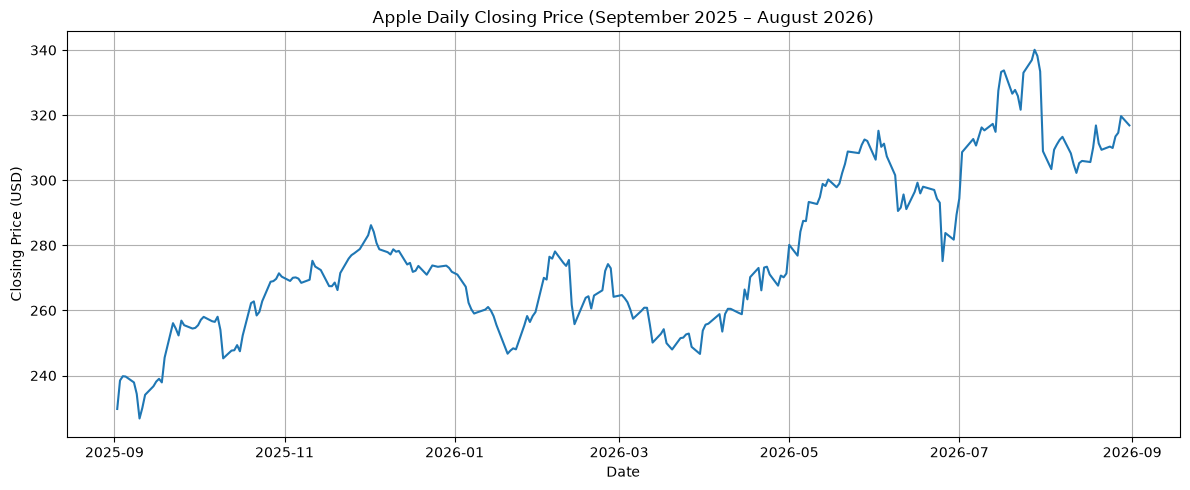

In [7]:
plt.figure(figsize=(12, 5))

plt.plot(df["Date"], df["Close"])

plt.title("Apple Daily Closing Price (September 2025 – August 2026)")
plt.xlabel("Date")
plt.ylabel("Closing Price (USD)")
plt.grid(True)
plt.tight_layout()
plt.savefig("figures/daily_close.png", dpi=300, bbox_inches="tight")
plt.show()

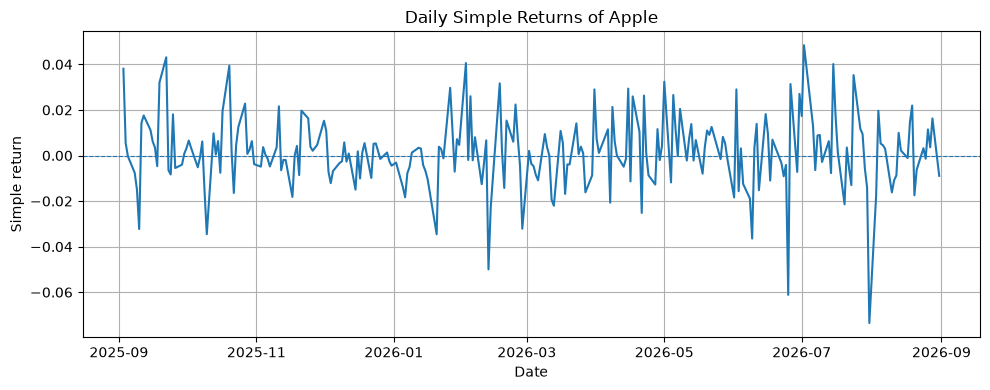

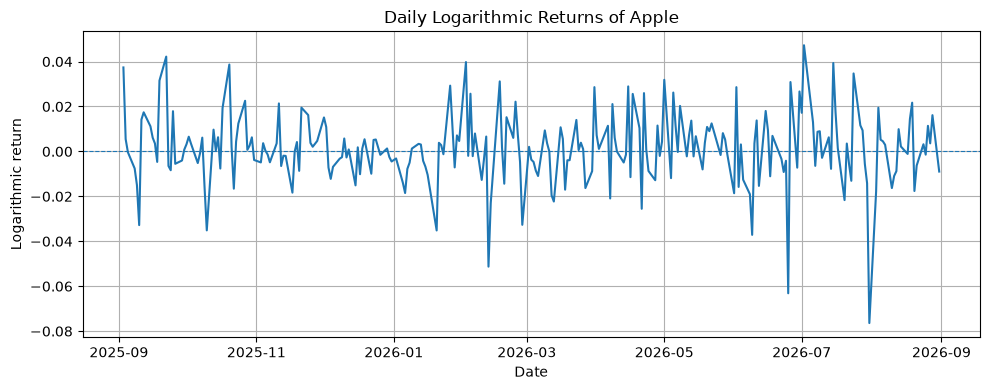

In [8]:
# Calculate daily simple and logarithmic returns
df["Return"] = df["Close"].pct_change()
df["Log_Return"] = np.log(df["Close"] / df["Close"].shift(1))

# Removes the first row, for which no return can be calculated
returns_df = df.dropna(subset=["Return", "Log_Return"]).copy()

# Plot 1: Daily simple returns
plt.figure(figsize=(10, 4))
plt.plot(returns_df["Date"], returns_df["Return"])
plt.axhline(0, linewidth=0.8, linestyle="--")
plt.title("Daily Simple Returns of Apple")
plt.xlabel("Date")
plt.ylabel("Simple return")
plt.grid(True)
plt.tight_layout()
plt.savefig("figures/daily_simple_returns.png", dpi=300, bbox_inches="tight")
plt.show()

# Plot 2: Daily logarithmic returns
plt.figure(figsize=(10, 4))
plt.plot(returns_df["Date"], returns_df["Log_Return"])
plt.axhline(0, linewidth=0.8, linestyle="--")
plt.title("Daily Logarithmic Returns of Apple")
plt.xlabel("Date")
plt.ylabel("Logarithmic return")
plt.grid(True)
plt.tight_layout()
plt.savefig("figures/daily_log_returns.png", dpi=300, bbox_inches="tight")
plt.show()

## Question 1b — Statistics

In [ ]:
#caclulation of the mean of the log returns by hand
mu_hat = (np.sum(returns_df["Log_Return"]))/len(returns_df["Log_Return"])
#calculation of the variance of the log returns by hand
sigma_hat_squared = (np.sum(((returns_df["Log_Return"])-mu_hat)**2))/(len(returns_df["Log_Return"])-1)
#prints of the calculated values
print(mu_hat)
print(sigma_hat_squared)


0.0012862691990937205
0.0002521334406149157


In [ ]:
#check if the calculation by hand is identical to the pandas functions
mu_hat = returns_df["Log_Return"].mean()
sigma_hat_squared = returns_df["Log_Return"].var()
#prints of the functions.
print("Sample mean:", mu_hat)
print("Sample variance:", sigma_hat_squared)

Sample mean: 0.0012862691990937205
Sample variance: 0.0002521334406149157


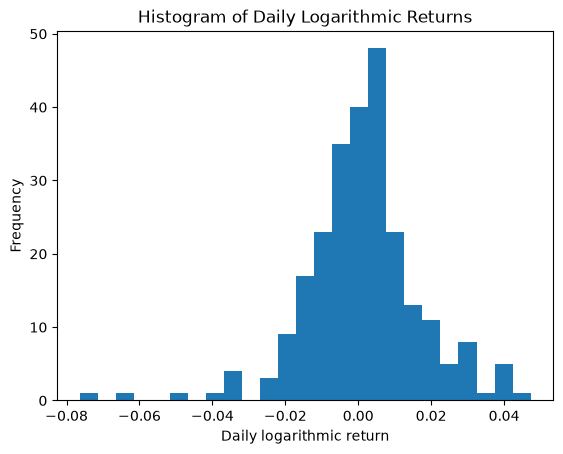

In [47]:
# Histogram plot of the daily logarithmic returns
plt.hist(returns_df["Log_Return"], bins=25)

plt.xlabel("Daily logarithmic return")
plt.ylabel("Frequency")
plt.title("Histogram of Daily Logarithmic Returns")

# Save the figure for the Overleaf report
plt.savefig("figures/daily_log_histogram.png", dpi=300, bbox_inches="tight")

plt.show()

In [ ]:
# Sort the observed daily logarithmic returns
empirical_quantiles = np.sort(returns_df["Log_Return"].dropna())

# Number of observations
M = len(empirical_quantiles)

print("Number of returns:", M)
print("Smallest return:", empirical_quantiles[0])
print("Largest return:", empirical_quantiles[-1])

Number of returns: 250
Smallest return: -0.07638297593538608
Largest return: 0.047271698660718856


In [ ]:
from statistics import NormalDist
#defining the normal distribution
normal_dist = NormalDist(
    mu=mu_hat,
    sigma=np.sqrt(sigma_hat_squared)
)
i = np.arange(1, M + 1)
#taking the probabilities
probabilities = (i - 0.5) / M
theoretical_quantiles = np.array([
    normal_dist.inv_cdf(p) for p in probabilities
])
#test if the theoretical_quantiles behaves like it should
print(theoretical_quantiles[:5])
print("Number of theoretical quantiles:", len(theoretical_quantiles))


[-0.04441523 -0.03860334 -0.03565313 -0.0336038  -0.03201023]
Number of theoretical quantiles: 250


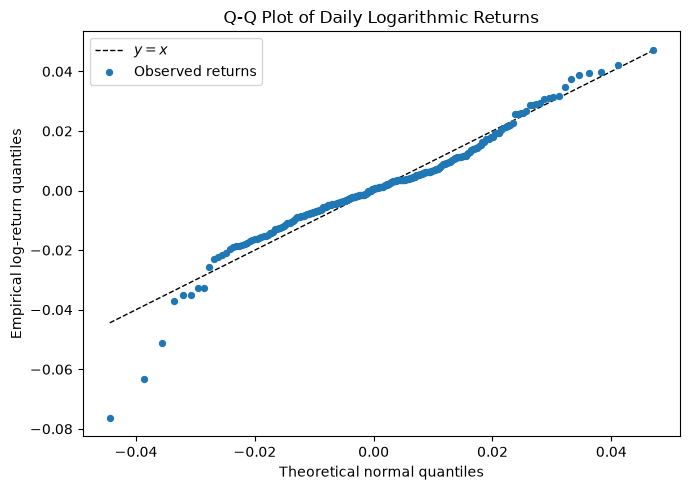

In [42]:
# Q-Q plot of daily logarithmic returns
plt.figure(figsize=(7, 5))

# Reference line, drawn first so it appears behind the points
lower = theoretical_quantiles.min()
upper = theoretical_quantiles.max()

plt.plot(
    [lower, upper], [lower, upper],
    color="black", linestyle="--", linewidth=1,
    label=r"$y=x$", zorder=1
)

# Observed quantiles
plt.scatter(
    theoretical_quantiles, empirical_quantiles,
    s=18, label="Observed returns", zorder=2
)

plt.xlabel("Theoretical normal quantiles")
plt.ylabel("Empirical log-return quantiles")
plt.title("Q-Q Plot of Daily Logarithmic Returns")
plt.legend()
plt.tight_layout()

plt.savefig("figures/daily_log_qq2025-2026.png", dpi=300, bbox_inches="tight")
plt.show()

In [49]:
# Combine weekly closing prices from 2022–2025
files = [
    "data/Download Data - STOCK_US_XNAS_AAPL_2022.csv",
    "data/Download Data - STOCK_US_XNAS_AAPL_2023.csv",
    "data/Download Data - STOCK_US_XNAS_AAPL_2024.csv",
    "data/Download Data - STOCK_US_XNAS_AAPL_2025.csv"
]
weekly_df = pd.concat(
    [pd.read_csv(file) for file in files],
    ignore_index=True
)

weekly_df["Date"] = pd.to_datetime(
    weekly_df["Date"], format="%m/%d/%Y"
)

weekly_df = (
    weekly_df
    .drop_duplicates(subset="Date")
    .sort_values("Date")
    .reset_index(drop=True)
)

weekly_df.head()
#check if combining went correctly
print("First date:", weekly_df["Date"].min())
print("Last date:", weekly_df["Date"].max())
print("Number of weekly prices:", len(weekly_df))

print(weekly_df[["Date", "Close"]].head())
print(weekly_df[["Date", "Close"]].tail())

First date: 2022-01-07 00:00:00
Last date: 2025-12-31 00:00:00
Number of weekly prices: 210
        Date   Close
0 2022-01-07  172.17
1 2022-01-14  173.07
2 2022-01-21  162.41
3 2022-01-28  170.33
4 2022-02-04  172.39
          Date   Close
205 2025-12-05  278.78
206 2025-12-12  278.28
207 2025-12-19  273.67
208 2025-12-26  273.40
209 2025-12-31  271.86


In [50]:
# Calculate weekly logarithmic returns
weekly_df["Log_Return"] = np.log(
    weekly_df["Close"] / weekly_df["Close"].shift(1)
)

weekly_returns = weekly_df["Log_Return"].dropna()
# Sample statistics of weekly log returns
mu_hat_weekly = weekly_returns.mean()
sigma_hat_squared_weekly = weekly_returns.var()

print("Number of weekly returns:", len(weekly_returns))
print("Sample mean:", mu_hat_weekly)
print("Sample variance:", sigma_hat_squared_weekly)

Number of weekly returns: 209
Sample mean: 0.002185669220663731
Sample variance: 0.0014650590246062533


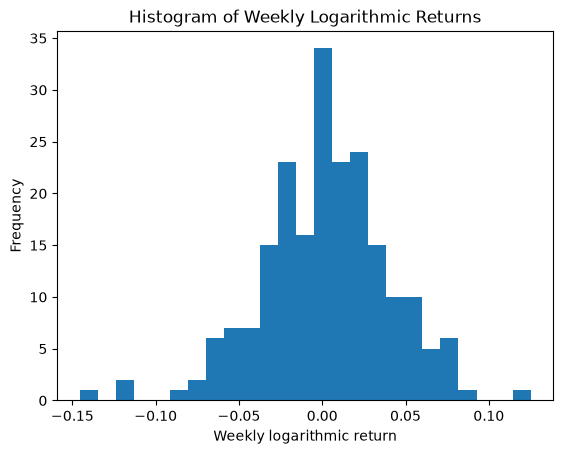

In [52]:
# Histogram of weekly logarithmic returns
plt.hist(weekly_returns, bins = 25)

plt.xlabel("Weekly logarithmic return")
plt.ylabel("Frequency")
plt.title("Histogram of Weekly Logarithmic Returns")

plt.savefig("figures/weekly_log_histogram.png",
            dpi=300, bbox_inches="tight")
plt.show()

In [53]:
# Sort the observed weekly log returns
weekly_empirical_quantiles = np.sort(weekly_returns)

# Assign probabilities to the observations
M_weekly = len(weekly_empirical_quantiles)
i_weekly = np.arange(1, M_weekly + 1)
probabilities_weekly = (i_weekly - 0.5) / M_weekly

# Fit a normal distribution using the weekly sample statistics
weekly_normal = NormalDist(
    mu=mu_hat_weekly,
    sigma=np.sqrt(sigma_hat_squared_weekly)
)

# Calculate the theoretical normal quantiles
weekly_theoretical_quantiles = np.array([
    weekly_normal.inv_cdf(p) for p in probabilities_weekly
])

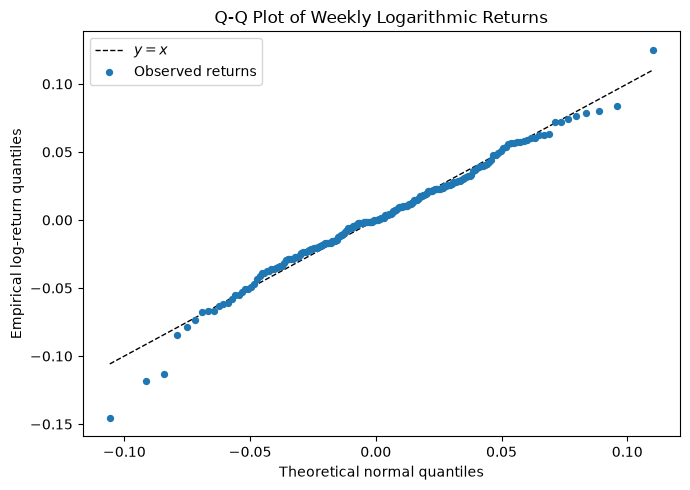

In [54]:
# Q-Q plot of weekly logarithmic returns
plt.figure(figsize=(7, 5))

lower = weekly_theoretical_quantiles.min()
upper = weekly_theoretical_quantiles.max()

# Reference line behind the observations
plt.plot(
    [lower, upper], [lower, upper],
    color="black", linestyle="--", linewidth=1,
    label=r"$y=x$", zorder=1
)

plt.scatter(
    weekly_theoretical_quantiles,
    weekly_empirical_quantiles,
    s=18, label="Observed returns", zorder=2
)

plt.xlabel("Theoretical normal quantiles")
plt.ylabel("Empirical log-return quantiles")
plt.title("Q-Q Plot of Weekly Logarithmic Returns")
plt.legend()
plt.tight_layout()

plt.savefig(
    "figures/weekly_log_qq.png",
    dpi=300, bbox_inches="tight"
)
plt.show()

## Question 2 - Monte Carlo

In [81]:
# Reproducible random numbers
rng = np.random.default_rng(42)

# Theoretical expectation
I_exact = 2.0

# Required sample sizes
sample_sizes = [10**2, 10**3, 10**4, 10**5]

# Number of independent Monte Carlo experiments per sample size
R = 1000

In [ ]:
#Defining the monte carlo function
def monte_carlo_estimate(M, rng):
    # Generate M independent uniform random variables
    U = rng.random(M)

    # Transform the samples
    Y = 1 / np.sqrt(U)

    # Monte Carlo estimate
    estimate = np.mean(Y)

    # Usual estimated standard error
    sample_std = np.std(Y, ddof=1)
    standard_error = sample_std / np.sqrt(M)

    # Usual normal-approximation 95% confidence interval
    ci_lower = estimate - 1.96 * standard_error
    ci_upper = estimate + 1.96 * standard_error

    return estimate, ci_lower, ci_upper

In [ ]:
#Run all experiments with the given M sizes
estimates_by_M = {}
first_run_results = {}

for M in sample_sizes:

    # Store the estimates from R independent experiments
    estimates = np.empty(R)

    for r in range(R):
        estimate, ci_lower, ci_upper = monte_carlo_estimate(M, rng)

        estimates[r] = estimate

        # Store the first run for the confidence-interval plot
        if r == 0:
            first_run_results[M] = (
                estimate, ci_lower, ci_upper
            )

    estimates_by_M[M] = estimates

    # Summary of the results
    errors = estimates - I_exact
    estimate, ci_lower, ci_upper = first_run_results[M]

    empirical_lower, empirical_upper = np.quantile(
        estimates, [0.025, 0.975]
    )

    print(f"\nM = {M:,}")
    print(f"First estimate: {estimate:.6f}")
    print(f"Normal-approximation 95% CI: "
          f"[{ci_lower:.6f}, {ci_upper:.6f}]")
    print(f"Median estimate across runs: "
          f"{np.median(estimates):.6f}")
    print(f"Empirical central 95% range across runs: "
          f"[{empirical_lower:.6f}, {empirical_upper:.6f}]")
    print(f"Median absolute error: "
          f"{np.median(np.abs(errors)):.6f}")


M = 100
First estimate: 1.877245
Normal-approximation 95% CI: [1.605441, 2.149048]
Median estimate across runs: 1.943219
Empirical central 95% range across runs: [1.654009, 2.704568]
Median absolute error: 0.144460

M = 1,000
First estimate: 1.894508
Normal-approximation 95% CI: [1.776499, 2.012518]
Median estimate across runs: 1.983108
Empirical central 95% range across runs: [1.863397, 2.217837]
Median absolute error: 0.056260

M = 10,000
First estimate: 1.968845
Normal-approximation 95% CI: [1.928371, 2.009320]
Median estimate across runs: 1.995608
Empirical central 95% range across runs: [1.945068, 2.068351]
Median absolute error: 0.020223

M = 100,000
First estimate: 1.991118
Normal-approximation 95% CI: [1.973969, 2.008267]
Median estimate across runs: 1.998920
Empirical central 95% range across runs: [1.979868, 2.027355]
Median absolute error: 0.007424


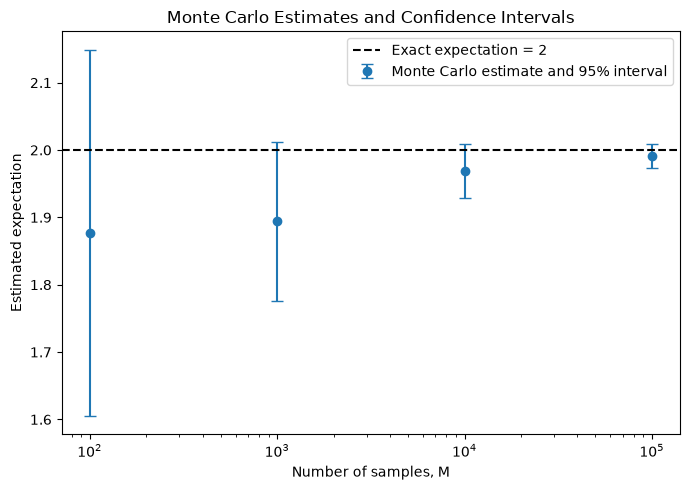

In [84]:
#Plot estimates and confidence intervals
point_estimates = [
    first_run_results[M][0] for M in sample_sizes
]

lower_errors = [
    first_run_results[M][0] - first_run_results[M][1]
    for M in sample_sizes
]

upper_errors = [
    first_run_results[M][2] - first_run_results[M][0]
    for M in sample_sizes
]

plt.figure(figsize=(7, 5))

plt.errorbar(
    sample_sizes,
    point_estimates,
    yerr=np.array([lower_errors, upper_errors]),
    fmt="o",
    capsize=4,
    label="Monte Carlo estimate and 95% interval"
)

plt.axhline(
    I_exact,
    color="black",
    linestyle="--",
    label="Exact expectation = 2"
)

plt.xscale("log")
plt.xlabel("Number of samples, M")
plt.ylabel("Estimated expectation")
plt.title("Monte Carlo Estimates and Confidence Intervals")
plt.legend()
plt.tight_layout()

plt.savefig(
    "figures/mc_estimates_ci.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

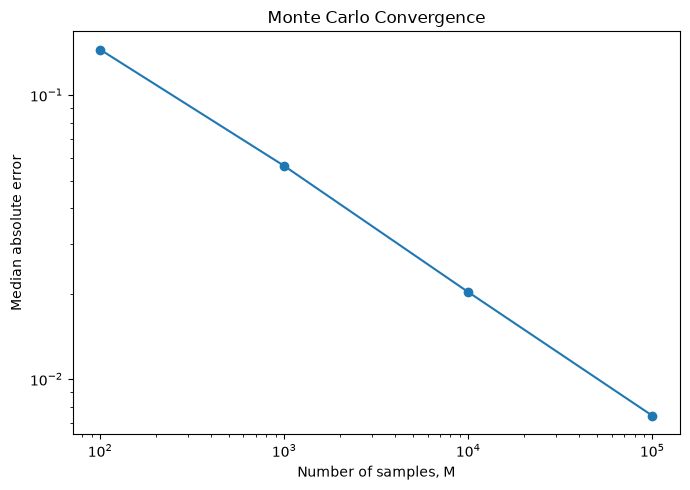

In [87]:
# Examine the speed of convergence
median_absolute_errors = [
    np.median(np.abs(estimates_by_M[M] - I_exact))
    for M in sample_sizes
]

plt.figure(figsize=(7, 5))

plt.plot(
    sample_sizes,
    median_absolute_errors,
    marker="o"
)

plt.xscale("log")
plt.yscale("log")
plt.xlabel("Number of samples, M")
plt.ylabel("Median absolute error")
plt.title("Monte Carlo Convergence")

plt.tight_layout()

plt.savefig(
    "figures/mc_convergence.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

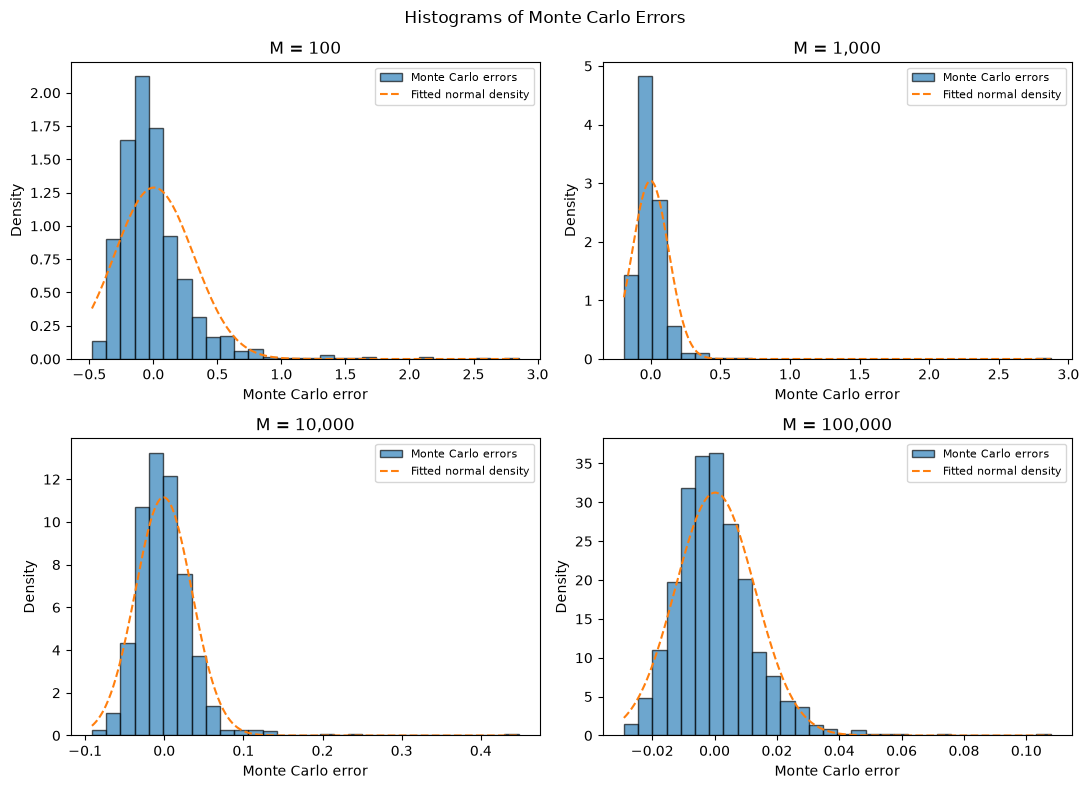

In [85]:
#histograms
fig, axes = plt.subplots(2, 2, figsize=(11, 8))

for ax, M in zip(axes.flat, sample_sizes):

    errors = estimates_by_M[M] - I_exact

    # Estimate parameters of a fitted normal distribution
    error_mean = np.mean(errors)
    error_std = np.std(errors, ddof=1)

    # Histogram of errors
    ax.hist(
        errors,
        bins=30,
        density=True,
        alpha=0.65,
        edgecolor="black",
        label="Monte Carlo errors"
    )

    # Fitted normal density
    x = np.linspace(errors.min(), errors.max(), 500)

    normal_density = (
        1 / (error_std * np.sqrt(2 * np.pi))
        * np.exp(-0.5 * ((x - error_mean) / error_std)**2)
    )

    ax.plot(
        x,
        normal_density,
        linestyle="--",
        label="Fitted normal density"
    )

    ax.set_title(f"M = {M:,}")
    ax.set_xlabel("Monte Carlo error")
    ax.set_ylabel("Density")
    ax.legend(fontsize=8)

fig.suptitle("Histograms of Monte Carlo Errors")
fig.tight_layout()

fig.savefig(
    "figures/mc_error_histograms.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

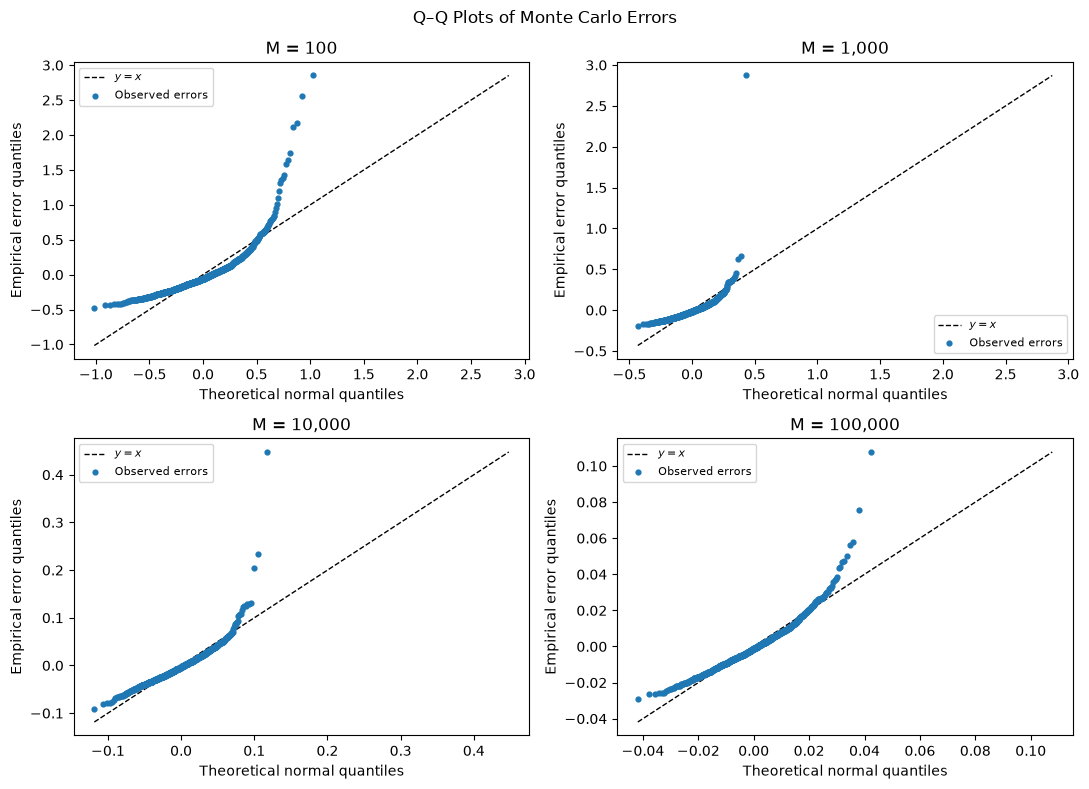

In [86]:
#qqplots
fig, axes = plt.subplots(2, 2, figsize=(11, 8))

for ax, M in zip(axes.flat, sample_sizes):

    errors = estimates_by_M[M] - I_exact

    # Sort the observed errors
    empirical_quantiles = np.sort(errors)
    n = len(empirical_quantiles)

    # Assign plotting probabilities
    i = np.arange(1, n + 1)
    probabilities = (i - 0.5) / n

    # Fit a normal distribution to the errors
    error_mean = np.mean(errors)
    error_std = np.std(errors, ddof=1)

    fitted_normal = NormalDist(
        mu=error_mean,
        sigma=error_std
    )

    # Theoretical normal quantiles
    theoretical_quantiles = np.array([
        fitted_normal.inv_cdf(p)
        for p in probabilities
    ])

    # Reference line
    lower = min(
        theoretical_quantiles.min(),
        empirical_quantiles.min()
    )
    upper = max(
        theoretical_quantiles.max(),
        empirical_quantiles.max()
    )

    ax.plot(
        [lower, upper],
        [lower, upper],
        color="black",
        linestyle="--",
        linewidth=1,
        label=r"$y=x$",
        zorder=1
    )

    ax.scatter(
        theoretical_quantiles,
        empirical_quantiles,
        s=12,
        label="Observed errors",
        zorder=2
    )

    ax.set_title(f"M = {M:,}")
    ax.set_xlabel("Theoretical normal quantiles")
    ax.set_ylabel("Empirical error quantiles")
    ax.legend(fontsize=8)

fig.suptitle("Q–Q Plots of Monte Carlo Errors")
fig.tight_layout()

fig.savefig(
    "figures/mc_error_qq_plots.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

## Question 3 - Simulation of stock price paths.

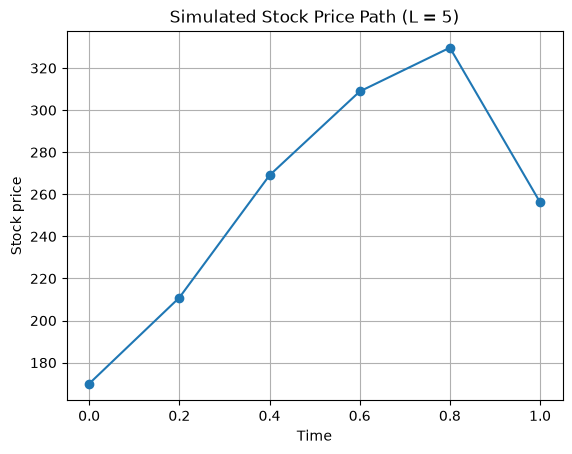

In [123]:
# Model parameters
T = 1
S0 = 170
mu = 0.1
sigma = 0.344
L = 5

# Time grid
dt = T / L
t = np.linspace(0, T, L + 1)

# Storage for the stock-price path
S = np.zeros(L + 1)
S[0] = S0

# Simulate the stock-price path
for i in range(L):
    Z = np.random.normal(0, 1)
    S[i + 1] = S[i] * (
        1 + mu * dt + sigma * np.sqrt(dt) * Z
    )

# Plot the stock-price path
plt.plot(t, S, marker="o")
plt.xlabel("Time")
plt.ylabel("Stock price")
plt.title("Simulated Stock Price Path (L = 5)")
plt.grid(True)
plt.savefig(
    "figures/stock_price_path_L5.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [121]:
#Now for 5000 runs
# Number of simulations
M = 5000

# Store the final stock price of each simulation
ST = np.zeros(M)

for m in range(M):

    # Initialize a new stock-price path
    S = np.zeros(L + 1)
    S[0] = S0

    # Simulate the path over L time steps
    for i in range(L):
        Z = np.random.normal(0, 1)

        S[i + 1] = S[i] * (
            1 + mu * dt + sigma * np.sqrt(dt) * Z
        )

    # Store the terminal stock price
    ST[m] = S[-1]
    

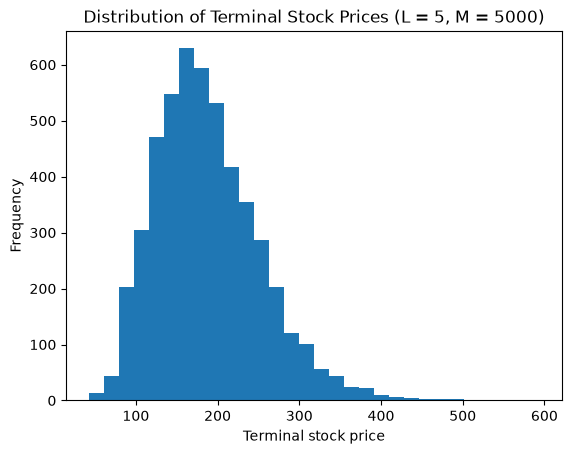

In [119]:
#Plotting the results of the 5000 runs in a histogram
plt.hist(ST, bins=30)

plt.xlabel("Terminal stock price")
plt.ylabel("Frequency")
plt.title("Distribution of Terminal Stock Prices (L = 5, M = 5000)")

plt.savefig(
    "figures/terminal_prices_L5.png",
    dpi=300,
    bbox_inches="tight"
)
plt.savefig(
    "figures/terminal_prices_L5.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [124]:
# Number of simulations and time-step counts
M = 5000
L_values = [5, 10, 20, 50, 100]

# Store the terminal prices for each L
terminal_prices = {}

for L in L_values:
    dt = T / L

    # Initialize M independent stock prices
    S = np.full(M, S0)

    # Simulate all paths over L time steps
    for i in range(L):
        Z = np.random.normal(0, 1, M)
        S = S * (1 + mu * dt + sigma * np.sqrt(dt) * Z)

    # Store the terminal price of every path
    terminal_prices[L] = S

print("Number of terminal prices for each L:")
for L in L_values:
    print(f"L = {L}: {len(terminal_prices[L])}")

Number of terminal prices for each L:
L = 5: 5000
L = 10: 5000
L = 20: 5000
L = 50: 5000
L = 100: 5000


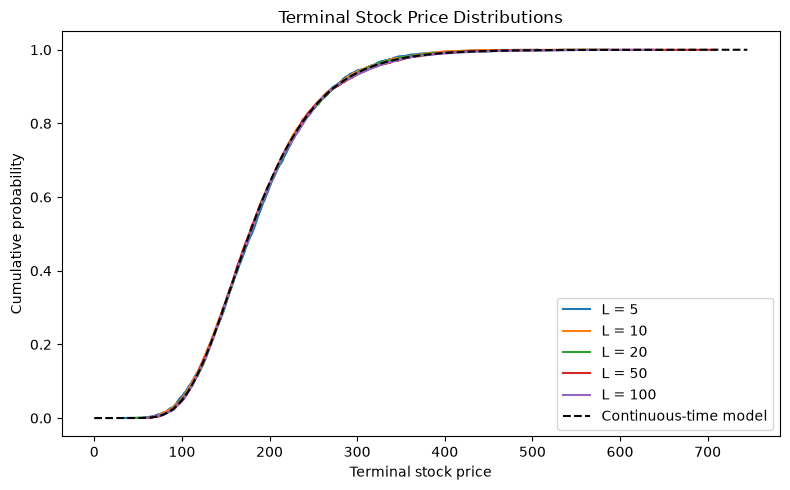

In [126]:
# Standard normal distribution
standard_normal = NormalDist()

# Values on the x-axis for the theoretical CDF
x_values = np.linspace(
    0.01,
    max(np.max(prices) for prices in terminal_prices.values()) * 1.05,
    1000
)

# Theoretical CDF of the continuous-time stock price model
z_values = (
    np.log(x_values / S0)
    - (mu - 0.5 * sigma**2) * T
) / (sigma * np.sqrt(T))

theoretical_cdf = np.array([
    standard_normal.cdf(z) for z in z_values
])

# Plot the empirical CDF for each number of time steps
plt.figure(figsize=(8, 5))

for L in L_values:
    sorted_prices = np.sort(terminal_prices[L])
    empirical_cdf = np.arange(1, M + 1) / M

    plt.step(
        sorted_prices,
        empirical_cdf,
        where="post",
        label=f"L = {L}"
    )

# Add the theoretical continuous-time CDF
plt.plot(
    x_values,
    theoretical_cdf,
    "k--",
    label="Continuous-time model"
)

plt.xlabel("Terminal stock price")
plt.ylabel("Cumulative probability")
plt.title("Terminal Stock Price Distributions")
plt.legend()
plt.tight_layout()

plt.savefig(
    "figures/terminal_cdfs.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 3b

In [130]:
# Sample sizes for Question 3b
sample_sizes_3b = [10**2, 10**3, 10**4, 10**5]

# Random number generator
rng_3b = np.random.default_rng(42)

# Theoretical expectation
theoretical_mean_3b = S0 * np.exp(mu * T)

print("Theoretical expectation:", theoretical_mean_3b)

Theoretical expectation: 187.87905607286012


In [131]:
#standard results
# Store results and random numbers
standard_results_3b = {}
z_samples_3b = {}

for M in sample_sizes_3b:

    # Generate M independent standard normal samples
    Z = rng_3b.standard_normal(M)
    z_samples_3b[M] = Z

    # Calculate the terminal stock prices
    terminal_prices_mc = S0 * np.exp(
        (mu - 0.5 * sigma**2) * T
        + sigma * np.sqrt(T) * Z
    )

    # Monte Carlo estimate
    estimate = np.mean(terminal_prices_mc)

    # Estimated standard error
    standard_error = (
        np.std(terminal_prices_mc, ddof=1) / np.sqrt(M)
    )

    # 95% confidence interval
    lower = estimate - 1.96 * standard_error
    upper = estimate + 1.96 * standard_error

    # Store the results
    standard_results_3b[M] = {
        "estimate": estimate,
        "lower": lower,
        "upper": upper,
        "width": upper - lower
    }

    print(
        f"M = {M:6d} | "
        f"Estimate = {estimate:.4f} | "
        f"95% CI = [{lower:.4f}, {upper:.4f}]"
    )

M =    100 | Estimate = 180.2244 | 95% CI = [170.8242, 189.6245]
M =   1000 | Estimate = 186.6561 | 95% CI = [182.5678, 190.7444]
M =  10000 | Estimate = 187.6387 | 95% CI = [186.3208, 188.9565]
M = 100000 | Estimate = 187.7157 | 95% CI = [187.3005, 188.1310]


In [132]:
# Store antithetic results
antithetic_results_3b = {}

for M in sample_sizes_3b:

    # Reuse the same standard normal samples
    Z = z_samples_3b[M]

    # Terminal prices for Z and -Z
    S_plus = S0 * np.exp(
        (mu - 0.5 * sigma**2) * T
        + sigma * np.sqrt(T) * Z
    )

    S_minus = S0 * np.exp(
        (mu - 0.5 * sigma**2) * T
        - sigma * np.sqrt(T) * Z
    )

    # Average each antithetic pair
    pair_averages = (S_plus + S_minus) / 2

    # Antithetic Monte Carlo estimate
    estimate_A = np.mean(pair_averages)

    # Standard error based on the independent pair averages
    standard_error_A = (
        np.std(pair_averages, ddof=1) / np.sqrt(M)
    )

    # 95% confidence interval
    lower_A = estimate_A - 1.96 * standard_error_A
    upper_A = estimate_A + 1.96 * standard_error_A

    # Store results
    antithetic_results_3b[M] = {
        "estimate": estimate_A,
        "lower": lower_A,
        "upper": upper_A,
        "width": upper_A - lower_A
    }

    print(
        f"M = {M:6d} | "
        f"Estimate = {estimate_A:.4f} | "
        f"95% CI = [{lower_A:.4f}, {upper_A:.4f}]"
    )

M =    100 | Estimate = 183.4728 | 95% CI = [181.7731, 185.1725]
M =   1000 | Estimate = 187.9013 | 95% CI = [186.9050, 188.8976]
M =  10000 | Estimate = 188.0842 | 95% CI = [187.7670, 188.4014]
M = 100000 | Estimate = 187.9547 | 95% CI = [187.8560, 188.0534]


In [ ]:
#Comparison of the confidence interval widths
print("Comparison of confidence interval widths\n")

for M in sample_sizes_3b:

    standard_width = standard_results_3b[M]["width"]
    antithetic_width = antithetic_results_3b[M]["width"]

    ratio = standard_width / antithetic_width

    print(
        f"M = {M:6d} | "
        f"Standard width = {standard_width:.6f} | "
        f"Antithetic width = {antithetic_width:.6f} | "
        f"Ratio = {ratio:.4f}"
    )

Comparison of confidence interval widths

M =    100 | Standard width = 18.800287 | Antithetic width = 3.399368 | Ratio = 5.5305
M =   1000 | Standard width = 8.176619 | Antithetic width = 1.992638 | Ratio = 4.1034
M =  10000 | Standard width = 2.635649 | Antithetic width = 0.634374 | Ratio = 4.1547
M = 100000 | Standard width = 0.830474 | Antithetic width = 0.197440 | Ratio = 4.2062


## 4a Historic volatility

In [134]:
# Daily historical volatility
M_daily = len(returns_df["Log_Return"].dropna())
dt_daily = 1 / M_daily  # T = 1 year

sigma_daily = np.sqrt(
    returns_df["Log_Return"].var() / dt_daily
)

# Weekly historical volatility
M_weekly = len(weekly_returns)
dt_weekly = 4 / M_weekly  # T = 4 years

sigma_weekly = np.sqrt(
    weekly_returns.var() / dt_weekly
)

print("Daily historical volatility:", sigma_daily)
print("Weekly historical volatility:", sigma_weekly)

Daily historical volatility: 0.2510644541820465
Weekly historical volatility: 0.27667550313621325


## 4b Exponentially weighted moving average

In [137]:
#defining the function for calculating the ewma volatility
def calculate_ewma_volatility(log_returns, dt, w=0.94, window=20):
    U = np.asarray(log_returns, dtype=float)

    # Store the annualised volatility estimates
    variance_estimates = np.full(len(U), np.nan)

    # Initialise using the first 20 returns
    variance_estimates[window - 1] = np.mean(U[:window]**2) / dt

    # Update the estimate using EWMA
    for i in range(window, len(U)):
        variance_estimates[i] = (
            w * variance_estimates[i - 1]
            + (1 - w) * U[i]**2 / dt
        )

    return np.sqrt(variance_estimates)

In [138]:
#preparing the daily and weekly data for the plots

# Extract daily observations
daily_data = returns_df.dropna(subset=["Log_Return"]).copy()
daily_returns = daily_data["Log_Return"].to_numpy()
daily_dates = daily_data["Date"]

# Extract weekly observations
weekly_data = weekly_df.dropna(subset=["Log_Return"]).copy()
weekly_returns = weekly_data["Log_Return"].to_numpy()
weekly_dates = weekly_data["Date"]

# Time interval in years
dt_daily = 1 / len(daily_returns)
dt_weekly = 4 / len(weekly_returns)

# Calculate the EWMA volatility estimates
daily_ewma = calculate_ewma_volatility(daily_returns, dt_daily)
weekly_ewma = calculate_ewma_volatility(weekly_returns, dt_weekly)

# Full-sample volatility estimates for the dashed reference lines
daily_reference = np.sqrt(np.mean(daily_returns**2) / dt_daily)
weekly_reference = np.sqrt(np.mean(weekly_returns**2) / dt_weekly)

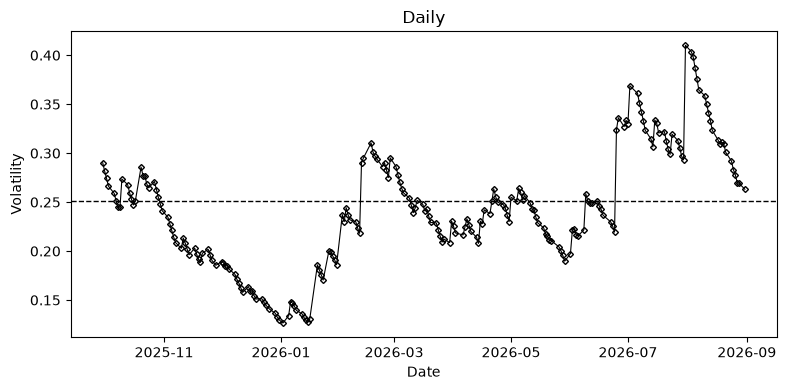

In [141]:
#plot of daily
plt.figure(figsize=(8, 4))

plt.plot(
    daily_dates,
    daily_ewma,
    color="black",
    linestyle="-",
    linewidth=0.8,
    marker="D",
    markersize=3,
    markerfacecolor="none",
    markeredgecolor="black",
    label="EWMA volatility"
)

plt.axhline(
    daily_reference,
    color="black",
    linestyle="--",
    linewidth=1,
    label="Full-sample estimate"
)

plt.xlabel("Date")
plt.ylabel("Volatility")
plt.title("Daily")
plt.tight_layout()

plt.savefig(
    "figures/daily_ewma_volatility.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

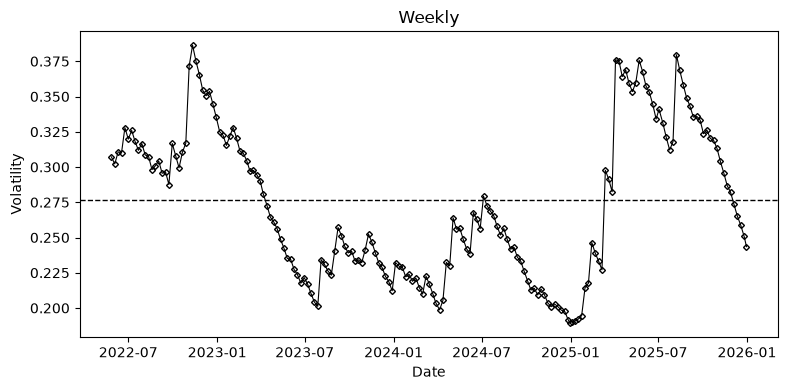

In [142]:
#Plot of weekly
plt.figure(figsize=(8, 4))

plt.plot(
    weekly_dates,
    weekly_ewma,
    color="black",
    linestyle="-",
    linewidth=0.8,
    marker="D",
    markersize=3,
    markerfacecolor="none",
    markeredgecolor="black",
    label="EWMA volatility"
)

plt.axhline(
    weekly_reference,
    color="black",
    linestyle="--",
    linewidth=1,
    label="Full-sample estimate"
)

plt.xlabel("Date")
plt.ylabel("Volatility")
plt.title("Weekly")
plt.tight_layout()

plt.savefig(
    "figures/weekly_ewma_volatility.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()